In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

##Task 1

First 5 rows of the dataset:
        date  users  sessions      revenue
0 2026-01-01   1626      1978  4628.448047
1 2026-01-02   1959      2294  5804.565792
2 2026-01-03   1360      1804  5850.356986
3 2026-01-04   1794      1942  7039.490876
4 2026-01-05   1630      1788  7565.477783 

Correlation Matrix:
             users  sessions   revenue
users     1.000000  0.973957  0.887522
sessions  0.973957  1.000000  0.871186
revenue   0.887522  0.871186  1.000000 



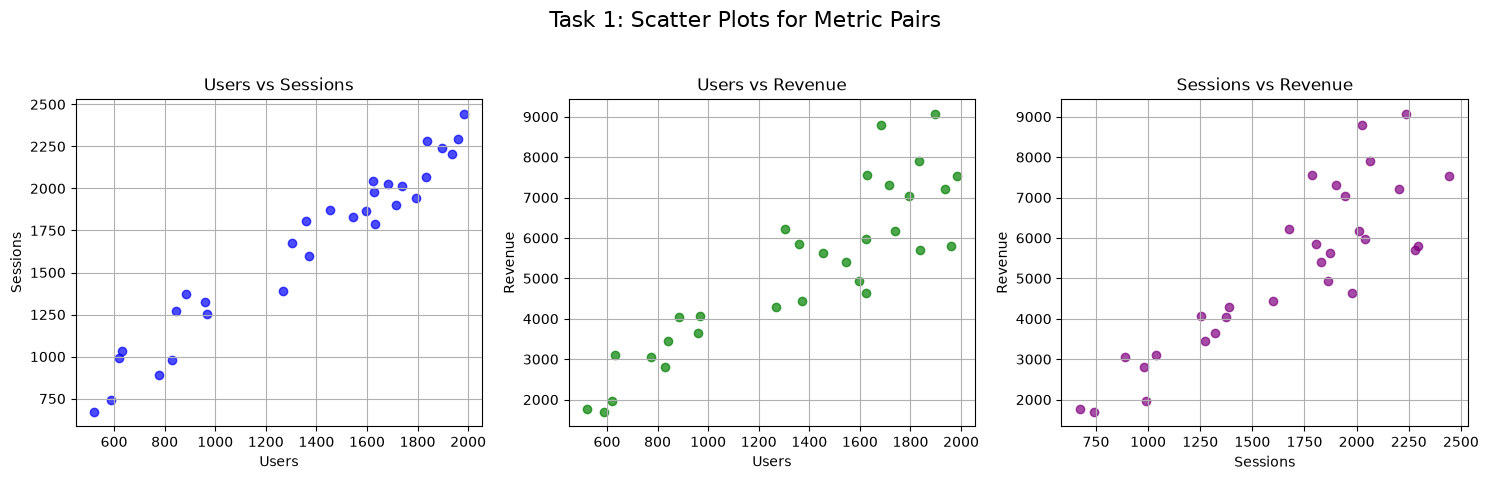

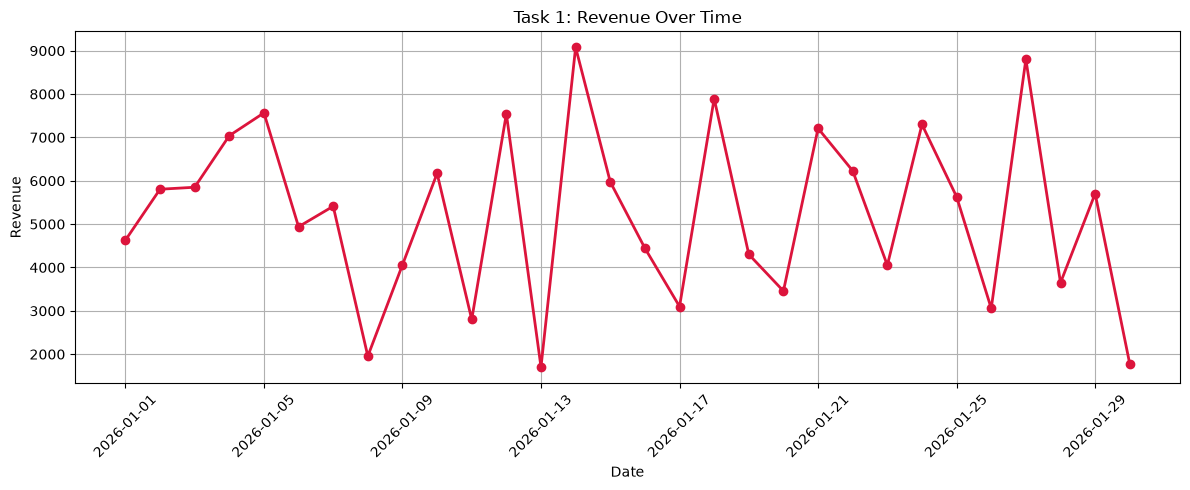

--------------------------------------------------


In [2]:

np.random.seed(42)
dates = pd.date_range(start="2026-01-01", periods=30, freq="D")
users = np.random.randint(500, 2000, size=30)

sessions = users + np.random.randint(100, 500, size=30)

revenue = users * np.random.uniform(2.5, 5.0, size=30) + np.random.normal(0, 200, size=30)

df_task1 = pd.DataFrame({
    "date": dates,
    "users": users,
    "sessions": sessions,
    "revenue": revenue
})

print("First 5 rows of the dataset:")
print(df_task1.head(), "\n")

corr_matrix = df_task1[["users", "sessions", "revenue"]].corr()
print("Correlation Matrix:")
print(corr_matrix, "\n")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle("Task 1: Scatter Plots for Metric Pairs", fontsize=16)

axes[0].scatter(df_task1["users"], df_task1["sessions"], color="blue", alpha=0.7)
axes[0].set_title("Users vs Sessions")
axes[0].set_xlabel("Users")
axes[0].set_ylabel("Sessions")
axes[0].grid(True)

axes[1].scatter(df_task1["users"], df_task1["revenue"], color="green", alpha=0.7)
axes[1].set_title("Users vs Revenue")
axes[1].set_xlabel("Users")
axes[1].set_ylabel("Revenue")
axes[1].grid(True)

axes[2].scatter(df_task1["sessions"], df_task1["revenue"], color="purple", alpha=0.7)
axes[2].set_title("Sessions vs Revenue")
axes[2].set_xlabel("Sessions")
axes[2].set_ylabel("Revenue")
axes[2].grid(True)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

plt.figure(figsize=(12, 5))
plt.plot(df_task1["date"], df_task1["revenue"], marker="o", color="crimson", linewidth=2)
plt.title("Task 1: Revenue Over Time")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
print("-" * 50)

##Task 2

Group A Conversion: 0.0867 (8.67%)
Group B Conversion: 0.1867 (18.67%)
Absolute Difference: 0.1000
Relative Change: 115.38%

Group A 95% CI: [0.0416, 0.1317]
Group B 95% CI: [0.1243, 0.2490]



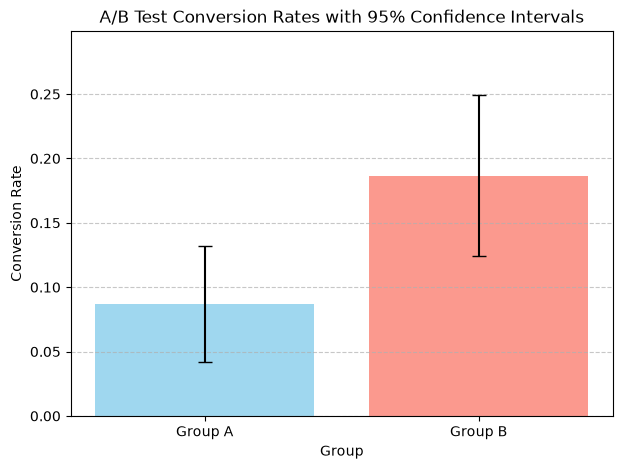

--------------------------------------------------


In [3]:
np.random.seed(10)
n_obs = 150
group_a = np.random.binomial(1, 0.12, size=n_obs)  # 12% conversion for A
group_b = np.random.binomial(1, 0.18, size=n_obs)  # 18% conversion for B

df_ab = pd.DataFrame({
    "group": ["A"] * n_obs + ["B"] * n_obs,
    "converted": np.concatenate([group_a, group_b])
})

conv_a = df_ab[df_ab["group"] == "A"]["converted"].mean()
conv_b = df_ab[df_ab["group"] == "B"]["converted"].mean()

abs_diff = conv_b - conv_a
rel_change = (abs_diff / conv_a) * 100

print(f"Group A Conversion: {conv_a:.4f} ({conv_a*100:.2f}%)")
print(f"Group B Conversion: {conv_b:.4f} ({conv_b*100:.2f}%)")
print(f"Absolute Difference: {abs_diff:.4f}")
print(f"Relative Change: {rel_change:.2f}%\n")

# CI = p ± 1.96 * sqrt(p*(1-p)/n)
def calc_ci(p, n):
    se = np.sqrt((p * (1 - p)) / n)
    margin = 1.96 * se
    return margin

margin_a = calc_ci(conv_a, n_obs)
margin_b = calc_ci(conv_b, n_obs)

print(f"Group A 95% CI: [{conv_a - margin_a:.4f}, {conv_a + margin_a:.4f}]")
print(f"Group B 95% CI: [{conv_b - margin_b:.4f}, {conv_b + margin_b:.4f}]\n")

plt.figure(figsize=(7, 5))
groups = ["Group A", "Group B"]
conversions = [conv_a, conv_b]
errors = [margin_a, margin_b]

plt.bar(groups, conversions, yerr=errors, capsize=5, color=["skyblue", "salmon"], alpha=0.8)
plt.title("A/B Test Conversion Rates with 95% Confidence Intervals")
plt.xlabel("Group")
plt.ylabel("Conversion Rate")
plt.ylim(0, max(conversions) + max(errors) + 0.05)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()
print("-" * 50)

##Task 3

Sample size n = 10:
  Mean of sample means: 2.0127
  Standard deviation of sample means: 0.6395

Sample size n = 100:
  Mean of sample means: 2.0110
  Standard deviation of sample means: 0.2010



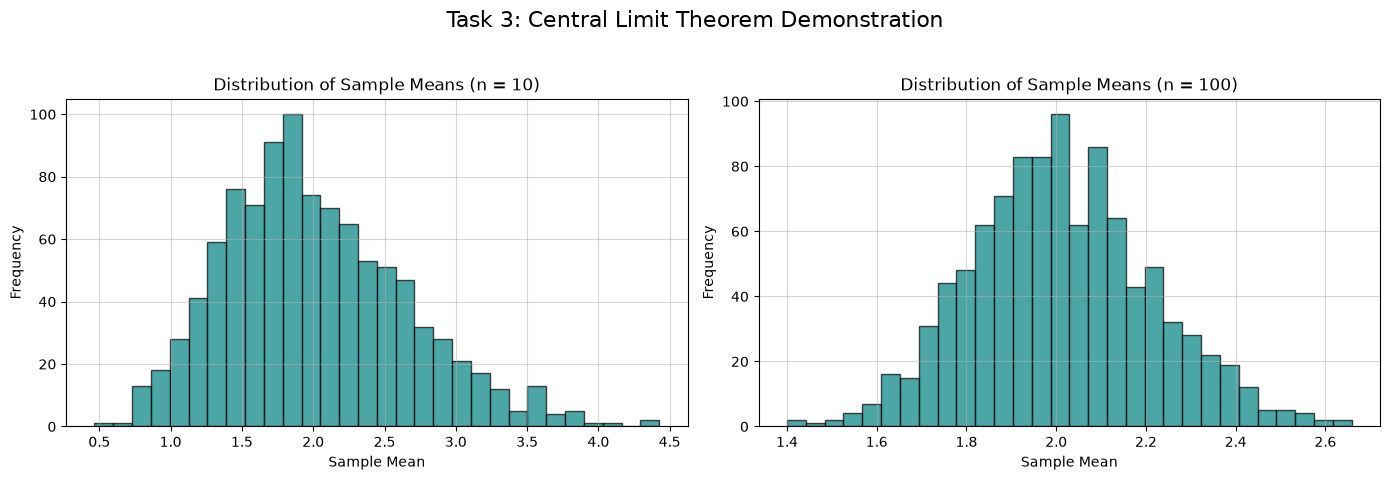

--------------------------------------------------


In [4]:
np.random.seed(42)
population = np.random.exponential(scale=2.0, size=60000)

# 2-5. Form subsamples of fixed size n, compute means, and repeat for at least two different n values
sample_sizes = [10, 100]
n_samples = 1000

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Task 3: Central Limit Theorem Demonstration", fontsize=16)

for idx, n in enumerate(sample_sizes):
    sample_means = []
    for _ in range(n_samples):
        sample = np.random.choice(population, size=n, replace=True)
        sample_means.append(np.mean(sample))
    
    sample_means = np.array(sample_means)
    mean_of_means = np.mean(sample_means)
    std_of_means = np.std(sample_means, ddof=1)
    
    print(f"Sample size n = {n}:")
    print(f"  Mean of sample means: {mean_of_means:.4f}")
    print(f"  Standard deviation of sample means: {std_of_means:.4f}\n")
    
    # Build histogram
    axes[idx].hist(sample_means, bins=30, color="teal", edgecolor="black", alpha=0.7)
    axes[idx].set_title(f"Distribution of Sample Means (n = {n})")
    axes[idx].set_xlabel("Sample Mean")
    axes[idx].set_ylabel("Frequency")
    axes[idx].grid(True, alpha=0.5)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()
print("-" * 50)

##Task 4

First 10 rows of the table with new rolling columns:
        date      sales  rolling_mean  rolling_std
0 2026-01-01  34.396479           NaN          NaN
1 2026-01-02  52.399298           NaN          NaN
2 2026-01-03  49.191101           NaN          NaN
3 2026-01-04  43.410564           NaN          NaN
4 2026-01-05  74.779319           NaN          NaN
5 2026-01-06  58.426950           NaN          NaN
6 2026-01-07  57.839111     52.920403    12.780715
7 2026-01-08  78.696276     59.248946    13.044710
8 2026-01-09  57.406993     59.964331    12.740221
9 2026-01-10  59.065510     61.374961    11.865185 



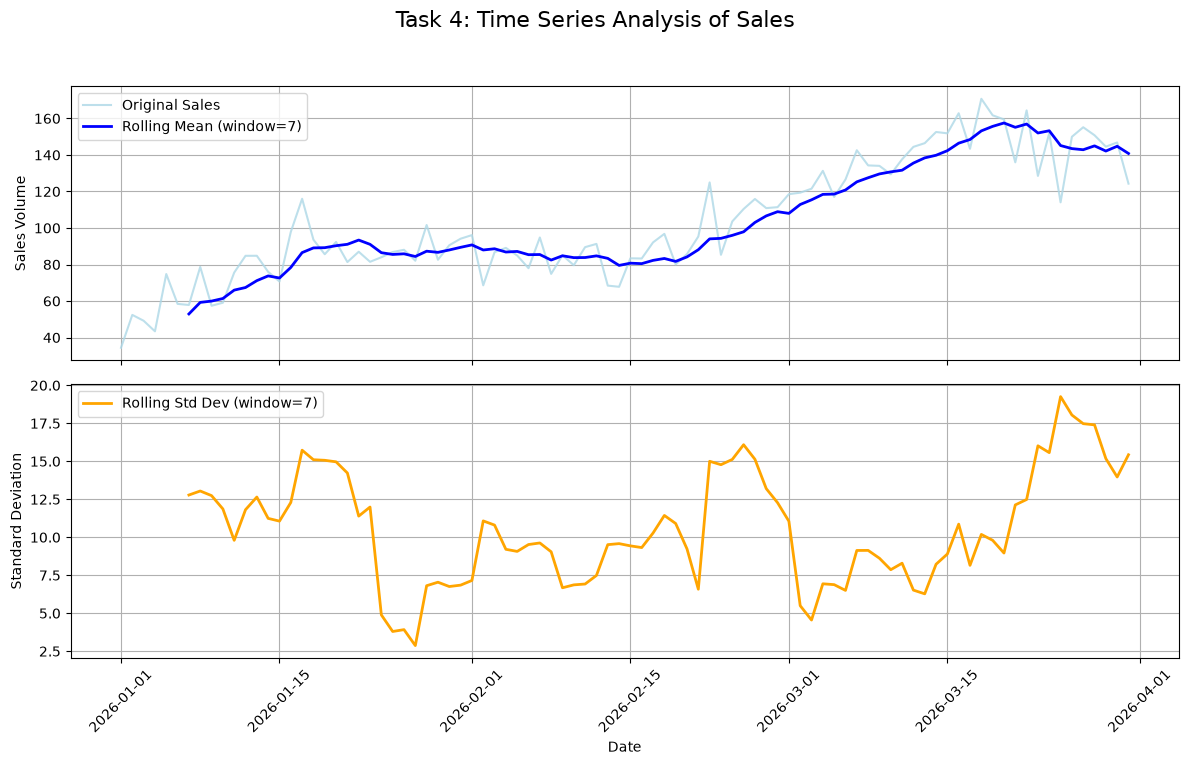

In [5]:

np.random.seed(50)
dates_90 = pd.date_range(start="2026-01-01", periods=90, freq="D")

trend = np.linspace(50, 150, 90)
seasonality = 15 * np.sin(np.linspace(0, 3 * np.pi, 90))
noise = np.random.normal(0, 10, 90)
sales = trend + seasonality + noise

df_task4 = pd.DataFrame({
    "date": dates_90,
    "sales": sales
})

window_size = 7
df_task4["rolling_mean"] = df_task4["sales"].rolling(window=window_size).mean()
df_task4["rolling_std"] = df_task4["sales"].rolling(window=window_size).std()

print("First 10 rows of the table with new rolling columns:")
print(df_task4.head(10), "\n")


fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
fig.suptitle("Task 4: Time Series Analysis of Sales", fontsize=16)

ax1.plot(df_task4["date"], df_task4["sales"], label="Original Sales", color="lightblue", alpha=0.8)
ax1.plot(df_task4["date"], df_task4["rolling_mean"], label=f"Rolling Mean (window={window_size})", color="blue", linewidth=2)
ax1.set_ylabel("Sales Volume")
ax1.legend(loc="upper left")
ax1.grid(True)

ax2.plot(df_task4["date"], df_task4["rolling_std"], label=f"Rolling Std Dev (window={window_size})", color="orange", linewidth=2)
ax2.set_xlabel("Date")
ax2.set_ylabel("Standard Deviation")
ax2.legend(loc="upper left")
ax2.grid(True)

plt.xticks(rotation=45)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()